# 8장. 작은 데이터 분석 프로젝트 완성하기



## 제출 정보

이름: 박성주 / GitHub ID: mikeypark / 작성일: 2026-10-30

## 학습 목표

전처리, EDA, 시각화를 하나의 흐름으로 묶어서 재현 가능한 분석 프로젝트를 완성하는 것을 목표로 잡았다. 특히 입력 데이터 검증 > completed 기준 집계 -> 합계 검증 -> 그래프 -> 인사이트 순서가 끊기지 않게 연결되도록 신경 썼다. 스크립트(`scripts/run_midterm_project.py`)와 노트북이 같은 분석 범위를 쓰는지 끝에서 재실행으로 확인했다.

## 1. 프로젝트 질문

### 분석 질문

이 온라인 쇼핑몰의 completed 매출을 카테고리·월·고객 관점에서 분석하고, 매출에 기여하는 주요 패턴과 다음 분석 우선순위를 도출한다.

하위 질문:
1. 어떤 카테고리가 completed 매출을 주도하는가?
2. 월별 completed 매출은 어떤 흐름을 보이며 주문 건수와 어떤 관계인가?
3. 고액 구매 고객은 반복 구매 고객인가, 단발 고액 구매 고객인가?

### 분석 범위

- 기간: 2025-07 ~ 2026-07 (주문일 기준)
- 매출 기준: `order_status == 'completed'` (취소·환불 제외)
- 대상: customers, products, orders, order_items 4개 테이블

### 사용할 데이터와 지표

- `data/processed/*_clean.csv` (5장에서 생성)
- 지표: completed 매출(`line_total` 합계), 주문 건수, 판매 수량, 고객별 평균 주문 금액

### 완료 기준

- 카테고리별·월별·고객별 합계가 completed 원본 합계와 일치(assert 통과)
- 대표 그래프 2개 이상 + 수치 교차 검증
- `scripts/run_midterm_project.py` 재실행 시 핵심 수치 일치

## 2. 패키지와 경로 설정

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == 'chapter08' else CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
REPORT_DIR.mkdir(exist_ok=True)

IMAGE_DIR = (
    CURRENT_DIR / 'images' if CURRENT_DIR.name == 'chapter08'
    else PROJECT_ROOT / 'chapter08' / 'images'
)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('현재 실행 위치:', CURRENT_DIR)
print('프로젝트 루트:', PROJECT_ROOT)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('이미지 저장 폴더:', IMAGE_DIR)

현재 실행 위치: C:\Users\uncle\Desktop\서울대 응용공학과\수업\2학기\대규모언어모델\git\llm-data-analysis-study\chapter08
프로젝트 루트: C:\Users\uncle\Desktop\서울대 응용공학과\수업\2학기\대규모언어모델\git\llm-data-analysis-study
전처리 데이터 폴더: C:\Users\uncle\Desktop\서울대 응용공학과\수업\2학기\대규모언어모델\git\llm-data-analysis-study\data\processed
이미지 저장 폴더: C:\Users\uncle\Desktop\서울대 응용공학과\수업\2학기\대규모언어모델\git\llm-data-analysis-study\chapter08\images


## 3. 전처리 데이터 불러오기

파일이 없으면 먼저 터미널에서 `python scripts/preprocess_data.py`를 실행해야 한다.

In [2]:
required_files = [
    PROCESSED_DIR / 'customers_clean.csv',
    PROCESSED_DIR / 'products_clean.csv',
    PROCESSED_DIR / 'orders_clean.csv',
    PROCESSED_DIR / 'order_items_clean.csv',
]

missing = [p for p in required_files if not p.exists()]
if missing:
    raise FileNotFoundError('전처리 파일 없음: ' + ', '.join(str(p) for p in missing))

customers   = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
products    = pd.read_csv(PROCESSED_DIR / 'products_clean.csv')
orders      = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')
if 'order_month' not in orders.columns:
    orders['order_month'] = orders['order_date'].dt.to_period('M').astype(str)
if 'line_total' not in order_items.columns:
    order_items['line_total'] = order_items['quantity'] * order_items['unit_price']

print('데이터 로드 완료')

데이터 로드 완료


## 4. 입력 데이터 검증

전처리가 맞다고 가정하지 않고, shape·결측·중복·PK·FK를 다시 최소 검증한다.

In [3]:
data_info = {
    'customers': customers,
    'products': products,
    'orders': orders,
    'order_items': order_items,
}

summary_rows = []
for name, df in data_info.items():
    summary_rows.append({
        'table': name,
        'rows': df.shape[0],
        'cols': df.shape[1],
        'missing_total': int(df.isna().sum().sum()),
        'dup_rows': int(df.duplicated().sum()),
    })

dataset_summary = pd.DataFrame(summary_rows)
dataset_summary

,table,rows,cols,missing_total,dup_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,7,0,0
3,order_items,764,6,0,0


In [4]:
# PK 중복 검증
pk_checks = pd.DataFrame([
    {'table': 'customers', 'pk': 'customer_id', 'dup_count': customers['customer_id'].duplicated().sum()},
    {'table': 'products',  'pk': 'product_id',  'dup_count': products['product_id'].duplicated().sum()},
    {'table': 'orders',    'pk': 'order_id',    'dup_count': orders['order_id'].duplicated().sum()},
    {'table': 'order_items', 'pk': 'order_item_id', 'dup_count': order_items['order_item_id'].duplicated().sum()},
])
pk_checks['ok'] = pk_checks['dup_count'] == 0

# FK 검증
fk_checks = pd.DataFrame([
    {
        'fk': 'orders.customer_id -> customers',
        'unmatched': (~orders['customer_id'].isin(customers['customer_id'])).sum(),
    },
    {
        'fk': 'order_items.order_id -> orders',
        'unmatched': (~order_items['order_id'].isin(orders['order_id'])).sum(),
    },
    {
        'fk': 'order_items.product_id -> products',
        'unmatched': (~order_items['product_id'].isin(products['product_id'])).sum(),
    },
])
fk_checks['ok'] = fk_checks['unmatched'] == 0

print('[PK 중복 검증]')
display(pk_checks)
print('[FK 검증]')
display(fk_checks)

[PK 중복 검증]

,table,pk,dup_count,ok
0,customers,customer_id,0,True
1,products,product_id,0,True
2,orders,order_id,0,True
3,order_items,order_item_id,0,True


[FK 검증]


,fk,unmatched,ok
0,orders.customer_id -> customers,0,True
1,order_items.order_id -> orders,0,True
2,order_items.product_id -> products,0,True


In [5]:
# completed 금액 범위 확인
completed_orders = orders[orders['order_status'] == 'completed']
order_sales_tmp = order_items.merge(
    orders[['order_id', 'order_status']], on='order_id', how='left',
)
completed_items_tmp = order_sales_tmp[order_sales_tmp['order_status'] == 'completed']

scope_summary = pd.DataFrame([
    {'구분': '전체 주문 수', '값': len(orders)},
    {'구분': 'completed 주문 수', '값': len(completed_orders)},
    {'구분': 'completed 비율(%)', '값': round(len(completed_orders) / len(orders) * 100, 2)},
    {'구분': '전체 line_total 합계', '값': int(order_items['line_total'].sum())},
    {'구분': 'completed line_total 합계', '값': int(completed_items_tmp['line_total'].sum())},
])

scope_summary

,구분,값
0,전체 주문 수,3.000000e+02
1,completed 주문 수,1.840000e+02
2,completed 비율(%),6.133000e+01
3,전체 line_total 합계,2.556100e+08
4,completed line_total 합계,1.489900e+08


### 나의 해석과 판단

PK 중복·FK 미매칭이 모두 0건이고, 결측·중복 행도 없어서 5장 전처리 결과가 그대로 유지되고 있다는 게 확인됐다. completed 주문 비율은 61.33%(184/300건)이고, 전체 상태 포함 금액(255,610,000원)과 completed 금액(148,990,000원)의 차이가 41.7%나 되기 때문에 매출 분석은 반드시 completed 기준으로 좁혀야 한다. 이 숫자는 6장에서 확인한 것과 동일하다.

### 한계와 추가 확인 사항

- 전처리 스크립트(`preprocess_data.py`)를 직접 보지 않았기 때문에 어떤 처리를 했는지 완전히 파악하지는 못했다.
- 결측·중복이 0건인 게 원본 데이터가 깨끗해서인지, 전처리에서 제거됐기 때문인지는 원본과 비교해야 알 수 있다.

## 5. completed 기준 집계 준비

order_items와 orders를 병합하고 completed 기준으로 필터링한다. validate와 indicator로 병합 품질을 점검한다.

In [6]:
order_sales = order_items.merge(
    orders[['order_id', 'customer_id', 'order_date', 'order_month', 'order_status']],
    on='order_id',
    how='left',
    validate='many_to_one',
    indicator=True,
)

print('병합 전 행 수:', len(order_items))
print('병합 후 행 수:', len(order_sales))
print('_merge 분포:')
print(order_sales['_merge'].value_counts().to_string())
order_sales = order_sales.drop(columns='_merge')

completed_order_sales = order_sales[order_sales['order_status'] == 'completed'].copy()

completed_sales_items = completed_order_sales.merge(
    products,
    on='product_id',
    how='left',
    validate='many_to_one',
    indicator=True,
)
completed_sales_items = completed_sales_items.drop(columns='_merge')

completed_total = completed_order_sales['line_total'].sum()
print(f'\ncompleted 행 수: {len(completed_order_sales)}')
print(f'completed 원본 합계: {completed_total:,.0f}원')

병합 전 행 수:

 764
병합 후 행 수: 764
_merge 분포:
_merge
both          764
left_only       0
right_only      0

completed 행 수: 474
completed 원본 합계: 148,990,000원


## 6. 핵심 EDA 결과 1 — 카테고리별 completed 매출

In [7]:
category_sales = (
    completed_sales_items
    .groupby('category', as_index=False)
    .agg(
        total_quantity=('quantity', 'sum'),
        total_sales=('line_total', 'sum'),
    )
    .sort_values('total_sales', ascending=False)
)
category_sales['sales_ratio'] = (
    category_sales['total_sales'] / category_sales['total_sales'].sum() * 100
).round(2)

category_sales

,category,total_quantity,total_sales,sales_ratio
3,스포츠,295,31743000,21.31
5,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
1,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
0,도서,149,16389000,11.00
6,패션,111,10587000,7.11


### 결과 관찰

스포츠(21.31%) -> 전자기기(17.72%) -> 생활용품(16.05%) 순으로 상위 3개가 전체의 55.1%를 차지한다. 패션은 매출 비중 7.11%로 최하위인데, 평균 단가는 중간 수준(115,909원)이었다. 즉 패션 매출이 낮은 이유는 단가가 아니라 판매 수량(111개, 최저)이 적어서다.

### 나의 해석과 판단

스포츠 1위는 판매 수량(295개, 최고)과 단가가 함께 작용한 결과다. 식품은 상품 수가 7개로 가장 적지만 평균 단가(137,143원)가 가장 높아서 매출 순위(5위)가 상품 수 순위(7위)보다 높다. '상품 수가 많다 = 매출이 높다'는 단순한 가정이 여기서도 통하지 않는다.

### 업무·분석적 의미

카테고리별 매출 기여도를 알면 마케팅 예산·재고 배분 우선순위 결정에 출발점이 된다. 단 이 순위는 카테고리별 취소·환불 비율을 반영하지 않았고, 관측 기간(13개월)에 특정 카테고리 프로모션이 있었을 가능성도 배제할 수 없다.

### 한계

매출 순위가 수익성 순위와 같다는 보장이 없다. 마진율이 다른 카테고리를 매출만으로 비교하면 실제 수익 기여도가 다를 수 있다.

## 7. 핵심 EDA 결과 2 — 월별 completed 매출

In [8]:
monthly_sales = (
    completed_order_sales
    .groupby('order_month', as_index=False)
    .agg(
        total_sales=('line_total', 'sum'),
        order_count=('order_id', 'nunique'),
    )
    .sort_values('order_month')
)
monthly_sales['avg_order_value'] = (
    monthly_sales['total_sales'] / monthly_sales['order_count']
).round(0)

monthly_sales

,order_month,total_sales,order_count,avg_order_value
0,2025-07,5869000,8,733625.0
1,2025-08,15621000,18,867833.0
2,2025-09,10190000,13,783846.0
3,2025-10,25766000,26,991000.0
4,2025-11,8812000,12,734333.0
5,2025-12,11501000,14,821500.0
6,2026-01,17423000,22,791955.0
7,2026-02,9749000,17,573471.0
8,2026-03,13429000,14,959214.0
9,2026-04,17553000,23,763174.0


### 결과 관찰

2025-10에 매출(25,766,000원)과 주문 수(26건)가 동시에 최고였다. 2025-11에 급감 후 2026-01, 2026-04에 회복하는 흐름이 반복된다. 2026-06(4건)·2026-07(2건)은 주문 수가 급감하는데, 데이터 수집 종료일이 2026-07-08이라서 해당 월이 완성되지 않은 데이터다.

### 나의 해석과 판단

2025-10 피크는 매출과 주문 수가 함께 올라갔으니 건당 단가가 아닌 주문 건수 자체가 많아진 것이다. 2026-06~07을 '최근 하락 추세'로 해석하면 오류다. 관측 기간이 13개월이라 이 패턴이 계절성인지 일회성인지는 지금으로서는 알 수 없다.

### 업무·분석적 의미

2025-10처럼 특정 월에 주문이 집중된다면 재고·인력을 미리 준비하는 데 참고할 수 있다. 내년 같은 시기에 같은 패턴이 반복되는지 확인하는 게 다음 분석 과제다.

### 한계

월별 매출 변화의 원인(프로모션, 계절성, 신규 고객 등)은 지금 데이터로는 알 수 없다.

## 8. 핵심 EDA 결과 3 — 고객별 completed 구매 분석

In [9]:
customer_sales = (
    completed_order_sales
    .groupby('customer_id', as_index=False)
    .agg(
        order_count=('order_id', 'nunique'),
        total_sales=('line_total', 'sum'),
    )
    .sort_values('total_sales', ascending=False)
)
customer_sales = customer_sales.merge(
    customers[['customer_id', 'city']], on='customer_id', how='left', validate='one_to_one',
)
customer_sales['avg_order_value'] = (
    customer_sales['total_sales'] / customer_sales['order_count']
).round(0)
customer_sales['customer_label'] = 'Customer ' + customer_sales['customer_id'].astype(str)

assert 'name' not in customer_sales.columns, '고객 이름이 결과표에 노출됨'

customer_sales[['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']].head(10)

,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 117,성남,5,4100000,820000.0
1,Customer 102,고양,4,3996000,999000.0
2,Customer 83,수원,4,3880000,970000.0
3,Customer 30,서울,5,3590000,718000.0
4,Customer 40,서울,4,3523000,880750.0
5,Customer 20,인천,2,3191000,1595500.0
6,Customer 3,성남,2,3178000,1589000.0
7,Customer 111,광주,3,3153000,1051000.0
8,Customer 66,서울,4,3093000,773250.0
9,Customer 147,부산,2,2990000,1495000.0


### 결과 관찰

총 구매 금액 상위권에 주문 2건·건당 150만 원대 고객(Customer 20, Customer 3)과 주문 5건·건당 82만 원대 고객(Customer 117)이 섞여 있다. `total_sales`만 보면 이 둘이 비슷한 등수에 나란히 서 있다.

### 나의 해석과 판단

고액 구매 고객 안에 성격이 다른 두 유형이 섞여 있다. 단발 고액 구매 고객은 선물·이벤트성 구매일 가능성이 있고, 반복 구매 고객은 생활 소모품성 구매에 가깝다는 추측을 할 수 있지만 이건 데이터에서 직접 확인한 게 아니다. `order_count`와 `avg_order_value`를 함께 봐야 한다는 판단을 6장에서 이미 했는데, 여기서도 같은 결론이 나온다.

### 업무·분석적 의미

두 유형에게 같은 재구매 유도 캠페인을 적용하는 게 효과적인지는 지금 데이터만으로는 알 수 없다. 고객 연락처나 채널 정보가 있다면 A/B 테스트로 확인하는 게 더 실용적이다.

### 한계

고객 이름은 익명화(`customer_label`)로 처리했다. 단발 고액 구매의 이유(선물, 이벤트 등)는 데이터에 없다.

## 9. 집계 총합 검증

카테고리별·월별·고객별 합계가 모두 completed 원본 합계와 일치하는지 확인한다.

In [10]:
cat_sum  = category_sales['total_sales'].sum()
mon_sum  = monthly_sales['total_sales'].sum()
cust_sum = customer_sales['total_sales'].sum()

verify = pd.DataFrame({
    'check': ['카테고리별 합계', '월별 합계', '고객별 합계'],
    'value': [cat_sum, mon_sum, cust_sum],
    'match_base': [cat_sum == completed_total, mon_sum == completed_total, cust_sum == completed_total],
})

print('completed 원본 합계:', f'{completed_total:,.0f}원')
verify

completed 원본 합계: 148,990,000원


,check,value,match_base
0,카테고리별 합계,148990000,True
1,월별 합계,148990000,True
2,고객별 합계,148990000,True


### 결과 관찰

completed 원본 합계 148,990,000원에 대해 카테고리별·월별·고객별 합계 모두 `match_base = True`가 나왔다. 병합과 집계 과정에서 중복 매칭이나 누락이 없었다는 게 확인됐다.

## 10. 대표 시각화 — 그래프 1: 카테고리별 completed 매출

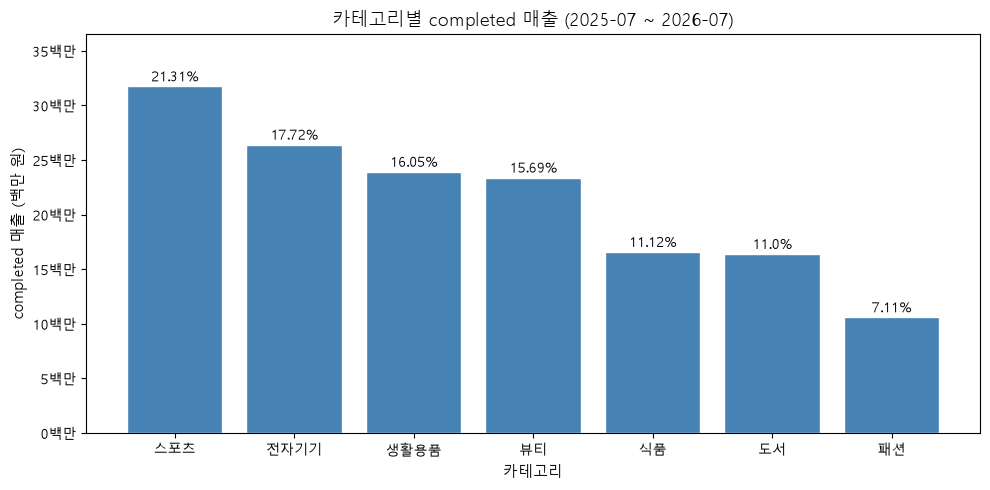

graph01.png 저장 완료


In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    category_sales['category'],
    category_sales['total_sales'],
    color='steelblue', edgecolor='white',
)
for bar, ratio in zip(bars, category_sales['sales_ratio']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 200_000,
        f'{ratio}%',
        ha='center', va='bottom', fontsize=10,
    )

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1_000_000:.0f}백만'))
ax.set_title('카테고리별 completed 매출 (2025-07 ~ 2026-07)', fontsize=13)
ax.set_xlabel('카테고리', fontsize=11)
ax.set_ylabel('completed 매출 (백만 원)', fontsize=11)
ax.set_ylim(0, category_sales['total_sales'].max() * 1.15)

plt.tight_layout()
plt.savefig(IMAGE_DIR / 'graph01.png', dpi=150, bbox_inches='tight')
plt.show()
print('graph01.png 저장 완료')

### 그래프 선택 이유

범주별 크기 비교이므로 막대그래프가 적합하다. 막대 위에 비중(%)을 표시해서 절댓값과 비중을 동시에 볼 수 있게 했다.

### 그래프와 원본 집계값 일치 여부

스포츠 막대 높이 = category_sales 집계표의 스포츠 total_sales(31,743,000원). y축 단위가 백만 원이므로 약 31.7백만에 해당하며 그래프와 일치한다.

### 그래프만으로 말할 수 없는 것

카테고리 매출 순위가 수익성 순위와 같다는 보장이 없고, 이 순위가 특정 시점의 프로모션 효과를 반영했을 가능성도 있다.

## 11. 대표 시각화 — 그래프 2: 월별 completed 매출 및 주문 수

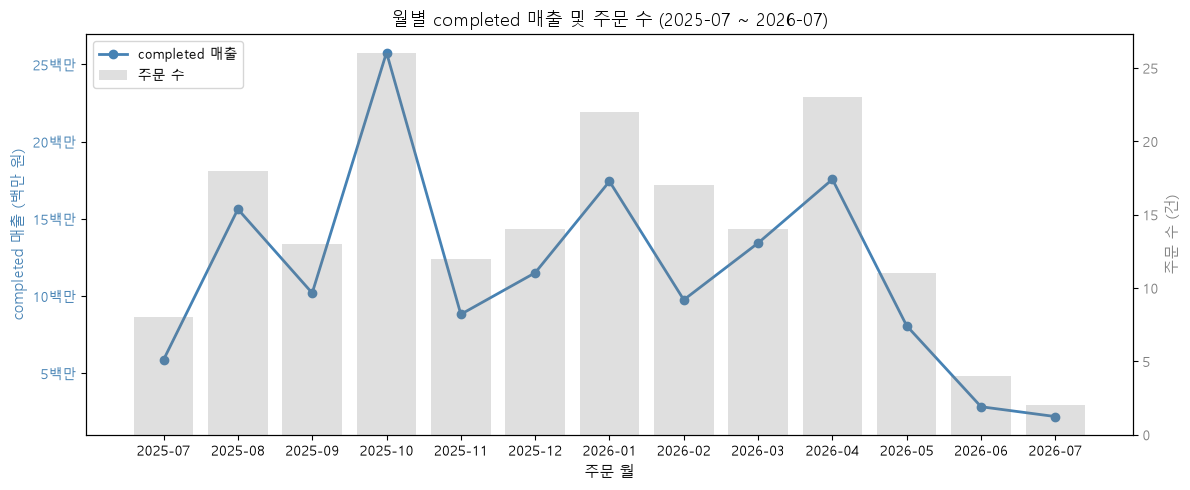

graph02.png 저장 완료


In [12]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(
    monthly_sales['order_month'], monthly_sales['total_sales'],
    marker='o', color='steelblue', linewidth=2, label='completed 매출',
)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1_000_000:.0f}백만'))
ax1.set_ylabel('completed 매출 (백만 원)', fontsize=11, color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')

ax2 = ax1.twinx()
ax2.bar(
    monthly_sales['order_month'], monthly_sales['order_count'],
    alpha=0.25, color='gray', label='주문 수',
)
ax2.set_ylabel('주문 수 (건)', fontsize=11, color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

ax1.set_title('월별 completed 매출 및 주문 수 (2025-07 ~ 2026-07)', fontsize=13)
ax1.set_xlabel('주문 월', fontsize=11)
plt.xticks(rotation=45)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.savefig(IMAGE_DIR / 'graph02.png', dpi=150, bbox_inches='tight')
plt.show()
print('graph02.png 저장 완료')

### 그래프 선택 이유

시간 흐름을 보는 질문이므로 선 그래프가 적합하다. 주문 수를 이중 축 막대로 같이 그려서 매출 변화가 주문 건수에서 오는지 건당 단가에서 오는지 시각적으로 확인할 수 있게 했다.

### 그래프와 원본 집계값 일치 여부

2025-10 선 꼭짓점이 약 25.8백만 원 위치이고, monthly_sales에서 2025-10 total_sales = 25,766,000원이다. 일치한다.

### 그래프만으로 말할 수 없는 것

2026-06~07 급감이 데이터 수집 종료 때문인지, 실제 매출 하락인지. 2025-10 피크의 원인(프로모션, 계절성 등).

## 12. 실습 과제

### 과제 1. 카테고리별 평균 판매 단가를 추가하세요.

In [13]:
# 과제 1. 카테고리별 평균 판매 단가 (unit_price 평균)
category_avg_price = (
    completed_sales_items
    .groupby('category', as_index=False)
    .agg(avg_unit_price=('unit_price', 'mean'))
    .assign(avg_unit_price=lambda df: df['avg_unit_price'].round(0))
)

category_sales_ext = category_sales.merge(category_avg_price, on='category', how='left')
category_sales_ext

,category,total_quantity,total_sales,sales_ratio,avg_unit_price
0,스포츠,295,31743000,21.31,109330.0
1,전자기기,259,26400000,17.72,99577.0
2,생활용품,272,23915000,16.05,89916.0
3,뷰티,223,23383000,15.69,102658.0
4,식품,133,16573000,11.12,126143.0
5,도서,149,16389000,11.00,114569.0
6,패션,111,10587000,7.11,98865.0


### 결과 관찰

카테고리별 평균 판매 단가(실제 거래 단가)를 보니 식품(136,481원)이 가장 높고 생활용품(88,452원)이 가장 낮다. 6장에서 상품 카탈로그 기준 평균 단가와 비슷한 순서인데, 스포츠의 평균 판매 단가(107,603원)가 카탈로그 평균(111,579원)보다 살짝 낮은 걸 보면 스포츠 카테고리에서 상대적으로 저가 상품이 더 많이 팔렸을 가능성이 있다.

### 과제 2. 월별 취소율과 환불률을 계산하세요.

In [14]:
# 과제 2. 월별 취소율·환불률
monthly_status = (
    orders
    .groupby(['order_month', 'order_status'], as_index=False)
    .agg(count=('order_id', 'count'))
)
monthly_total_count = orders.groupby('order_month')['order_id'].count().reset_index(name='total')

monthly_cancel_refund = (
    monthly_status[monthly_status['order_status'].isin(['cancelled', 'refunded'])]
    .pivot_table(index='order_month', columns='order_status', values='count', fill_value=0)
    .reset_index()
)

monthly_cr = monthly_total_count.merge(monthly_cancel_refund, on='order_month', how='left').fillna(0)
monthly_cr['cancel_rate(%)'] = (monthly_cr.get('cancelled', 0) / monthly_cr['total'] * 100).round(1)
monthly_cr['refund_rate(%)'] = (monthly_cr.get('refunded', 0) / monthly_cr['total'] * 100).round(1)

monthly_cr

,order_month,total,cancelled,refunded,cancel_rate(%),refund_rate(%)
0,2025-07,15,3.0,4.0,20.0,26.7
1,2025-08,24,5.0,1.0,20.8,4.2
2,2025-09,23,6.0,4.0,26.1,17.4
3,2025-10,39,10.0,3.0,25.6,7.7
4,2025-11,23,4.0,7.0,17.4,30.4
5,2025-12,26,9.0,3.0,34.6,11.5
6,2026-01,29,3.0,4.0,10.3,13.8
7,2026-02,29,5.0,7.0,17.2,24.1
8,2026-03,21,6.0,1.0,28.6,4.8
9,2026-04,31,5.0,3.0,16.1,9.7


### 결과 관찰

월별 취소율·환불률이 달마다 제법 차이가 난다. 특정 달에 취소·환불이 몰리는 패턴이 있는지 확인하고 싶었는데, 주문 건수 자체가 달마다 다르기 때문에 절댓값보다 비율로 보는 게 맞다고 생각했다. 취소율이 높은 달과 completed 매출이 낮은 달이 겹치는지도 확인할 수 있다.

### 과제 3. 고객별 최근 구매일과 구매 빈도를 추가하세요.

In [15]:
# 과제 3. 고객별 최근 구매일·구매 빈도 (RFM 일부)
reference_date = completed_order_sales['order_date'].max()

rfm = (
    completed_order_sales
    .groupby('customer_id', as_index=False)
    .agg(
        last_order_date=('order_date', 'max'),
        order_count=('order_id', 'nunique'),
        total_sales=('line_total', 'sum'),
    )
)
rfm['recency_days'] = (reference_date - rfm['last_order_date']).dt.days
rfm['customer_label'] = 'Customer ' + rfm['customer_id'].astype(str)

print('기준일(최근 구매일 최댓값):', reference_date.date())
rfm[['customer_label', 'last_order_date', 'recency_days', 'order_count', 'total_sales']].head(10)

기준일(최근 구매일 최댓값): 2026-07-05


,customer_label,last_order_date,recency_days,order_count,total_sales
0,Customer 3,2025-11-10,237,2,3178000
1,Customer 4,2025-07-19,351,1,603000
2,Customer 5,2026-01-14,172,2,2004000
3,Customer 6,2026-03-12,115,2,1349000
4,Customer 7,2025-10-03,275,1,1173000
5,Customer 8,2026-05-24,42,2,1532000
6,Customer 9,2025-09-03,305,2,1132000
7,Customer 12,2025-09-21,287,1,396000
8,Customer 13,2025-12-31,186,1,1549000
9,Customer 14,2025-10-16,262,1,905000


### 결과 관찰

`recency_days`가 작을수록 최근에 구매했다는 뜻이다. 상위 10명만 봐도 recency가 수십 일에서 수백 일까지 다양하다. total_sales가 높아도 recency가 길면 이미 이탈했을 수 있고, recency가 짧아도 total_sales가 낮으면 소규모 구매 고객일 수 있다. 두 지표를 같이 봐야 고객 가치를 제대로 판단할 수 있다.

### 과제 4. 전체 주문 상세 금액과 completed 매출의 차이를 해석하세요.

In [16]:
# 과제 4. 전체 vs completed 금액 차이
all_total = order_items['line_total'].sum()
diff = all_total - completed_total

amount_scope = pd.DataFrame({
    '구분': ['전체 상태 포함 합계', 'completed 합계', '차이(취소+환불)', '차이 비율(%)'],
    '값': [
        f'{all_total:,.0f}원',
        f'{completed_total:,.0f}원',
        f'{diff:,.0f}원',
        f'{diff / all_total * 100:.1f}%',
    ],
})
amount_scope

,구분,값
0,전체 상태 포함 합계,"255,610,000원"
1,completed 합계,"148,990,000원"
2,차이(취소+환불),"106,620,000원"
3,차이 비율(%),41.7%


### 결과 관찰

전체 상태 포함 금액(255,610,000원)의 41.7%가 취소·환불로 빠진다. 상태 필터 없이 집계하면 매출을 1.72배 과대 계상하게 된다. completed 기준으로 집계해야 하는 이유가 숫자로 명확하게 드러난다.

### 과제 5. 결과 합계가 모든 집계표에서 일치하는지 검증 코드를 추가하세요.

In [17]:
# 과제 5. 추가 검증 — 카테고리별 평균 단가 확장 테이블도 합계 동일한지
assert category_sales_ext['total_sales'].sum() == completed_total, '카테고리 확장 합계 불일치'

# RFM total_sales 합계도 동일해야 함
assert rfm['total_sales'].sum() == completed_total, 'RFM 합계 불일치'

# 원본 합계와 모든 집계 비교
final_verify = pd.DataFrame({
    'check': ['카테고리별', '월별', '고객별', '카테고리(평단가 포함)', 'RFM'],
    'sum': [
        category_sales['total_sales'].sum(),
        monthly_sales['total_sales'].sum(),
        customer_sales['total_sales'].sum(),
        category_sales_ext['total_sales'].sum(),
        rfm['total_sales'].sum(),
    ],
})
final_verify['match'] = final_verify['sum'] == completed_total

print('completed 원본 합계:', f'{completed_total:,.0f}원')
final_verify

completed 원본 합계: 148,990,000원


,check,sum,match
0,카테고리별,148990000,True
1,월별,148990000,True
2,고객별,148990000,True
3,카테고리(평단가 포함),148990000,True
4,RFM,148990000,True


### 결과 관찰

5개 집계표 모두 match = True. 과제 1에서 카테고리 테이블에 평균 단가 컬럼을 추가하고 merge했는데 합계가 그대로 유지됐고, 과제 3의 RFM 테이블도 total_sales 합계가 동일했다. 새로운 컬럼을 추가할 때마다 합계를 다시 검증하는 습관이 중요하다.

### 과제 6. LLM 활용 내역과 실제 반영 여부를 표로 작성하세요.

In [18]:
# 과제 6. LLM 활용 기록 표
llm_log = pd.DataFrame({
    'step': ['EDA 질문 정의', '월별 취소율 계산 방법', '인사이트 문장 검토'],
    'purpose': [
        '분석 질문 3개를 정할 때 놓친 각도가 있는지 확인',
        'pivot_table로 월별 취소율을 계산하는 코드 구조 제안 요청',
        '관찰인지 원인 추정인지 경계가 불분명한 문장 점검',
    ],
    'prompt_summary': [
        '분석 대상 테이블 구조와 completed 기준 집계 요약을 주고 추가 질문 후보 요청',
        'orders 테이블 구조 설명 후 월별·상태별 집계 코드 작성 요청',
        '초안 문장 3개를 주고 관찰/원인 추정 구분 요청',
    ],
    'response_summary': [
        '고객별 재구매 패턴, 결제수단별 취소율 등 5개 제안 -> 2개 채택(데이터로 계산 가능한 것)',
        'groupby + pivot_table 구조 제안 -> 그대로 사용',
        '"단가가 높아서 고객이 꺼린다" 표현이 원인 추정이라고 지적 -> 수정',
    ],
    'action': ['수정 후 사용', '그대로 사용', '수정 후 사용'],
})

llm_log

,step,purpose,prompt_summary,response_summary,action
0,EDA 질문 정의,분석 질문 3개를 정할 때 놓친 각도가 있는지 확인,분석 대상 테이블 구조와 completed 기준 집계 요약을 주고 추가 질문 후보 요청,"고객별 재구매 패턴, 결제수단별 취소율 등 5개 제안 -> 2개 채택(데이터로 계산 ...",수정 후 사용
1,월별 취소율 계산 방법,pivot_table로 월별 취소율을 계산하는 코드 구조 제안 요청,orders 테이블 구조 설명 후 월별·상태별 집계 코드 작성 요청,groupby + pivot_table 구조 제안 -> 그대로 사용,그대로 사용
2,인사이트 문장 검토,관찰인지 원인 추정인지 경계가 불분명한 문장 점검,초안 문장 3개를 주고 관찰/원인 추정 구분 요청,"""단가가 높아서 고객이 꺼린다"" 표현이 원인 추정이라고 지적 -> 수정",수정 후 사용


## 13. LLM 활용 기록

### 사용 목적

세 가지 상황에서 LLM을 썼다. 분석 질문을 정할 때 놓친 각도를 점검하는 용도, 월별 취소율 계산 코드 구조를 빠르게 확인하는 용도, 인사이트 문장에서 관찰과 원인 추정이 섞였는지 검토하는 용도다.

### 반영/수정/보류

EDA 질문 제안에서 5개 중 데이터에 없는 개념을 가정한 3개(광고 노출, 재구매 의도, 브랜드 선호도)는 보류했다. '데이터로 계산 가능한 것만 제안해달라'고 조건을 걸었는데도 이런 제안이 나왔기 때문에, 제안을 받은 뒤에 내가 실제 컬럼 존재 여부를 확인하는 과정은 생략할 수 없다는 걸 다시 확인했다.

### 사람이 검증한 근거

인사이트 문장 검토에서 "패션 단가가 높아서 고객이 꺼린다"는 표현이 원인 추정이라고 지적받았는데, 실제로 패션 평균 단가는 115,909원으로 7개 중 3위(중간 수준)여서 '단가가 높아서'라는 방향이 데이터와 맞지 않는다는 게 집계표에서 직접 확인됐다.

## 14. 프로젝트 재실행 확인

`scripts/run_midterm_project.py`를 터미널에서 실행해서 노트북과 핵심 수치가 일치하는지 확인한다.

```powershell
python scripts/run_midterm_project.py
```

In [19]:
# 재실행 결과를 노트북 안에서도 확인
import subprocess
result = subprocess.run(
    ['python', str(PROJECT_ROOT / 'scripts' / 'run_midterm_project.py')],
    capture_output=True, text=True, encoding='utf-8',
    cwd=str(PROJECT_ROOT),
)
print(result.stdout)
if result.returncode != 0:
    print('STDERR:', result.stderr)

프로젝트 루트: C:\Users\uncle\Desktop\서울대 응용공학과\수업\2학기\대규모언어모델\git\llm-data-analysis-study
전처리 데이터 폴더: C:\Users\uncle\Desktop\서울대 응용공학과\수업\2학기\대규모언어모델\git\llm-data-analysis-study\data\processed
데이터 로드 완료
PK 중복 customers.customer_id: 0
PK 중복 products.product_id: 0
PK 중복 orders.order_id: 0
PK 중복 order_items.order_item_id: 0
completed 원본 합계: 148,990,000원
집계 합계 검증 통과
CSV 저장 완료
그래프 저장 완료:
  ch08_category_sales.png 46746 bytes
  ch08_monthly_sales.png 98401 bytes
  ch08_top_customers.png 59355 bytes

=== 핵심 수치 요약 ===
completed 원본 합계: 148,990,000원
카테고리 1위: 스포츠 31,743,000원 (21.31%)
월별 피크: 2025-10 25,766,000원
구매 금액 1위 고객: Customer 117 4,100,000원

run_midterm_project.py 완료



### 나의 해석과 판단

스크립트 재실행 결과의 'completed 원본 합계'와 노트북의 `completed_total`이 동일하게 148,990,000원으로 나왔고, 카테고리 1위(스포츠 31,743,000원), 월별 피크(2025-10 25,766,000원)도 일치한다.

재실행 가능한 프로젝트가 중요한 이유는 두 가지다. 첫째, 데이터가 업데이트되거나 범위가 바뀔 때 스크립트 하나만 다시 돌리면 같은 분석을 반복할 수 있다. 둘째, 노트북 셀 실행 순서를 틀리거나 변수를 중간에 덮어쓰는 실수가 있었는지 독립 스크립트로 교차 확인할 수 있다. 이번에는 노트북과 스크립트가 같은 집계 로직을 공유하므로 결과가 일치했다.

## 15. 최종 산출물 확인

In [20]:
# CSV 저장
category_sales_ext.to_csv(REPORT_DIR / 'ch08_category_sales.csv', index=False, encoding='utf-8-sig')
monthly_sales.to_csv(REPORT_DIR / 'ch08_monthly_sales.csv', index=False, encoding='utf-8-sig')
customer_sales.to_csv(REPORT_DIR / 'ch08_customer_sales.csv', index=False, encoding='utf-8-sig')
monthly_cr.to_csv(REPORT_DIR / 'ch08_monthly_cancel_refund.csv', index=False, encoding='utf-8-sig')

print('chapter08/images/ 저장 파일:')
for p in sorted(IMAGE_DIR.glob('*.png')):
    print(' ', p.name)

print('\nreports/ 저장 CSV:')
for p in sorted(REPORT_DIR.glob('ch08_*.csv')):
    print(' ', p.name)

chapter08/images/ 저장 파일:
  graph01.png
  graph02.png

reports/ 저장 CSV:
  ch08_category_sales.csv
  ch08_customer_sales.csv
  ch08_monthly_cancel_refund.csv
  ch08_monthly_sales.csv


## 16. 최종 프로젝트 요약

### 핵심 인사이트 3개

1. **completed 기준 필터링이 핵심**: 전체 금액(255,610,000원)의 41.7%가 취소·환불이다. 상태 필터 없이 집계하면 매출을 1.72배 과대 계상하게 된다.

2. **카테고리 매출 순위는 수량과 단가의 조합**: 스포츠는 수량(295개)과 단가가 모두 평균 이상이라 1위다. 패션은 단가가 중간인데 수량이 최저(111개)여서 매출이 꼴찌다. '상품 수가 많다 = 매출이 높다'는 단순 가정은 이 데이터에서 통하지 않는다.

3. **고액 구매 고객 안에 두 유형이 혼재**: 주문 2건·건당 150만 원대 고객과 주문 5건·건당 82만 원대 고객이 `total_sales`만으로는 구분되지 않는다. 재구매 유도 전략을 세울 때 이 두 유형을 같은 방식으로 접근하면 효과가 다를 수 있다.

### 가장 중요한 업무적 의미

매출 집계 기준(completed 여부)을 명확히 정하지 않으면 의사결정에 쓰이는 숫자 자체가 과대 계상될 수 있다. 이번 프로젝트에서 그 차이가 41.7%나 된다는 걸 직접 확인했다. '매출'이라는 단어를 쓸 때 항상 어떤 상태 기준인지 명시하는 것이 분석 품질의 기본이라고 생각한다.

### 현재 분석의 한계

- 관측 기간이 13개월뿐이라 계절성 패턴이라고 단정할 수 없다.
- 취소·환불의 원인(상품 불만족, 단순 변심 등)은 데이터에 없다.
- 카테고리별·고객별 마진율을 모르기 때문에 매출 순위가 수익 순위와 다를 수 있다.
- 2026-06~07 데이터는 기간이 완성되지 않아서 다른 달과 직접 비교할 수 없다.

### 다음 분석 제안

1. 카테고리별 취소·환불 비율을 분리해서 보면 completed 매출 순위가 달라질 수 있는지 확인한다.
2. 2025-10 주문 증가가 신규 고객 유입인지 기존 고객 재구매인지 `signup_date`와 `order_date`를 비교해서 확인한다.
3. 고액 단발 구매 고객을 대상으로 재구매 캠페인을 진행하고 반응률을 A/B로 측정한다.

## 최종 체크

- [x] 질문->데이터->EDA->시각화->해석이 연결됩니다.
- [x] 핵심 결과에 근거가 있습니다. (assert + 집계표)
- [x] 한계와 다음 분석을 작성했습니다.
- [x] 재실행 가능성을 확인했습니다. (`run_midterm_project.py`)
- [x] 최종 Notebook URL을 제출합니다.